In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
WORK = '/content/drive/MyDrive/skinguard'
os.makedirs(WORK, exist_ok=True)
print("Work folder ready:", WORK)

Mounted at /content/drive
Work folder ready: /content/drive/MyDrive/skinguard


In [2]:
from google.colab import files
files.upload()   # choose kaggle.json when the file picker appears

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"sharnikrishna","key":"a5876b05f2b67549d143e43ef9fc12b9"}'}

In [3]:
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!pip -q install kaggle
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/ham --unzip
!ls /content/ham

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:53<00:00, 104MB/s]

ham10000_images_part_1	HAM10000_images_part_2	hmnist_28_28_RGB.csv
HAM10000_images_part_1	HAM10000_metadata.csv	hmnist_8_8_L.csv
ham10000_images_part_2	hmnist_28_28_L.csv	hmnist_8_8_RGB.csv


In [4]:
import pandas as pd, glob, os

meta = pd.read_csv('/content/ham/HAM10000_metadata.csv')
paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob('/content/ham/**/*.jpg', recursive=True)}
meta['path'] = meta['image_id'].map(paths)

print(meta.shape)
print("Missing image files:", meta['path'].isna().sum())
meta.head()

(10015, 8)
Missing image files: 0


,lesion_id,image_id,dx,dx_type,age,sex,localization,path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00274...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00250...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00267...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00256...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/ham/ham10000_images_part_2/ISIC_00316...


dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


<Axes: title={'center': 'HAM10000 class counts'}, xlabel='dx'>

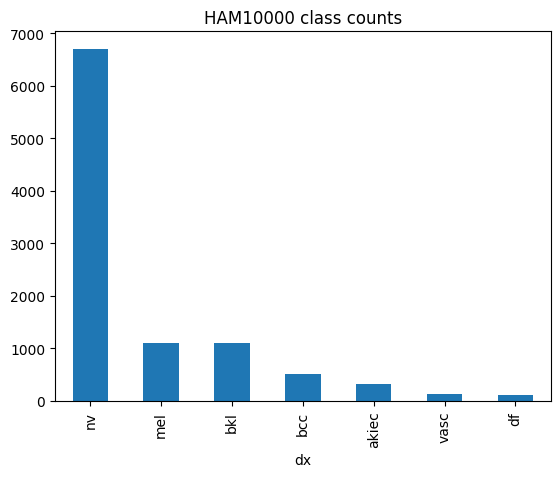

In [5]:
counts = meta['dx'].value_counts()
print(counts)
counts.plot(kind='bar', title='HAM10000 class counts')

In [6]:
from sklearn.model_selection import train_test_split

lesions = meta.drop_duplicates('lesion_id')[['lesion_id', 'dx']]

train_l, temp_l = train_test_split(lesions, test_size=0.30,
                                   stratify=lesions['dx'], random_state=42)
val_l, test_l = train_test_split(temp_l, test_size=0.50,
                                 stratify=temp_l['dx'], random_state=42)

train = meta[meta.lesion_id.isin(train_l.lesion_id)].copy()
val   = meta[meta.lesion_id.isin(val_l.lesion_id)].copy()
test  = meta[meta.lesion_id.isin(test_l.lesion_id)].copy()

print("Images:", len(train), len(val), len(test))

# leak check: all three must print 0
print(len(set(train.lesion_id) & set(val.lesion_id)))
print(len(set(train.lesion_id) & set(test.lesion_id)))
print(len(set(val.lesion_id) & set(test.lesion_id)))

# class counts per split
print(pd.DataFrame({'train': train.dx.value_counts(),
                    'val': val.dx.value_counts(),
                    'test': test.dx.value_counts()}))

Images: 7002 1532 1481
0
0
0
       train   val  test
dx                      
akiec    230    51    46
bcc      366    77    71
bkl      774   157   168
df        76    19    20
mel      778   170   165
nv      4679  1034   992
vasc      99    24    19


In [7]:
for name, df in [('train', train), ('val', val), ('test', test)]:
    df.to_csv(f'{WORK}/{name}.csv', index=False)
print(os.listdir(WORK))

['train.csv', 'val.csv', 'test.csv']


In [8]:
import pandas as pd
tr = pd.read_csv(f'{WORK}/train.csv'); va = pd.read_csv(f'{WORK}/val.csv'); te = pd.read_csv(f'{WORK}/test.csv')

print("Images:", len(tr), len(va), len(te), "| total:", len(tr)+len(va)+len(te))
print("Leaks (must be 0):",
      len(set(tr.lesion_id) & set(va.lesion_id)),
      len(set(tr.lesion_id) & set(te.lesion_id)),
      len(set(va.lesion_id) & set(te.lesion_id)))
print(pd.DataFrame({'train': tr.dx.value_counts(), 'val': va.dx.value_counts(), 'test': te.dx.value_counts()}))

Images: 7002 1532 1481 | total: 10015
Leaks (must be 0): 0 0 0
       train   val  test
dx                      
akiec    230    51    46
bcc      366    77    71
bkl      774   157   168
df        76    19    20
mel      778   170   165
nv      4679  1034   992
vasc      99    24    19


## Day 2: Training


In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, pandas as pd
WORK = '/content/drive/MyDrive/skinguard'

# download the dataset only if it is not already on this session's disk
if not os.path.exists('/content/ham/HAM10000_metadata.csv'):
    from google.colab import files
    files.upload()   # choose kaggle.json
    !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !pip -q install kaggle
    !kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/ham --unzip

tr = pd.read_csv(f'{WORK}/train.csv'); va = pd.read_csv(f'{WORK}/val.csv'); te = pd.read_csv(f'{WORK}/test.csv')
print(len(tr), len(va), len(te))

Mounted at /content/drive


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:43<00:00, 130MB/s]

7002 1532 1481


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, json, time, subprocess
import numpy as np, pandas as pd

WORK = '/content/drive/MyDrive/skinguard'
os.makedirs(WORK, exist_ok=True)

def sh(cmd): subprocess.run(cmd, shell=True, check=True)

if not os.path.exists('/content/ham/HAM10000_metadata.csv'):
    if not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
        from google.colab import files
        files.upload()   # choose kaggle.json
        sh('mkdir -p ~/.kaggle && mv /content/kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json')
    sh('pip -q install kaggle')
    sh('kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/ham --unzip')

paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob('/content/ham/**/*.jpg', recursive=True)}
tr = pd.read_csv(f'{WORK}/train.csv'); va = pd.read_csv(f'{WORK}/val.csv'); te = pd.read_csv(f'{WORK}/test.csv')
for df in (tr, va, te):
    df['path'] = df['image_id'].map(paths)

print(len(tr), len(va), len(te))
print("Missing paths:", tr.path.isna().sum(), va.path.isna().sum(), te.path.isna().sum())

import torch
print("GPU available:", torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
7002 1532 1481
Missing paths: 0 0 0
GPU available: True


In [3]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

CLASSES = ['akiec','bcc','bkl','df','mel','nv','vasc']   # fixed order, never change
cls2idx = {c: i for i, c in enumerate(CLASSES)}
IMG = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

class HAMDataset(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.labels = [cls2idx[d] for d in df['dx']]
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tf(img), self.labels[i]

train_dl = DataLoader(HAMDataset(tr, train_tf), batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(HAMDataset(va, eval_tf), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

xb, yb = next(iter(train_dl))
print(xb.shape, yb[:8])

torch.Size([32, 3, 224, 224]) tensor([2, 5, 5, 5, 5, 5, 1, 2])


In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(CLASSES))
model = model.to(device)

counts = tr['dx'].value_counts().reindex(CLASSES).values.astype(float)
w = (counts.sum() / counts) ** 0.5      # softened inverse-frequency weights
w = w / w.mean()
criterion = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device))
print(dict(zip(CLASSES, w.round(2))))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 155MB/s]


{'akiec': np.float64(1.1), 'bcc': np.float64(0.87), 'bkl': np.float64(0.6), 'df': np.float64(1.91), 'mel': np.float64(0.6), 'nv': np.float64(0.24), 'vasc': np.float64(1.68)}


In [5]:
from sklearn.metrics import recall_score

EPOCHS = 8
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = (device.type == 'cuda')
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
history, best_recall = [], 0.0

def evaluate(dl):
    model.eval(); loss_sum = 0; preds = []; labels = []
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            loss_sum += loss.item() * len(y)
            preds += out.argmax(1).cpu().tolist(); labels += y.cpu().tolist()
    preds, labels = np.array(preds), np.array(labels)
    return loss_sum/len(labels), (preds == labels).mean(), recall_score(labels, preds, average='macro', zero_division=0)

for epoch in range(1, EPOCHS + 1):
    t0 = time.time(); model.train(); running = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type=device.type, enabled=use_amp):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        running += loss.item() * len(y)
    scheduler.step()
    tr_loss = running / len(tr)
    v_loss, v_acc, v_rec = evaluate(val_dl)
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=v_loss, val_acc=float(v_acc), val_macro_recall=float(v_rec)))
    torch.save(model.state_dict(), f'{WORK}/last.pt')
    tag = ''
    if v_rec > best_recall:
        best_recall = v_rec; tag = '  <- best'
        torch.save(model.state_dict(), f'{WORK}/best.pt')
    json.dump(history, open(f'{WORK}/history.json', 'w'), indent=2)
    print(f"Epoch {epoch}/{EPOCHS} | train loss {tr_loss:.3f} | val loss {v_loss:.3f} | "
          f"val acc {v_acc:.3f} | val macro recall {v_rec:.3f} | {time.time()-t0:.0f}s{tag}")

Epoch 1/8 | train loss 1.013 | val loss 0.637 | val acc 0.757 | val macro recall 0.661 | 100s  <- best
Epoch 2/8 | train loss 0.655 | val loss 0.733 | val acc 0.713 | val macro recall 0.617 | 78s
Epoch 3/8 | train loss 0.530 | val loss 0.565 | val acc 0.793 | val macro recall 0.678 | 77s  <- best
Epoch 4/8 | train loss 0.429 | val loss 0.574 | val acc 0.796 | val macro recall 0.656 | 79s
Epoch 5/8 | train loss 0.338 | val loss 0.532 | val acc 0.810 | val macro recall 0.681 | 77s  <- best
Epoch 6/8 | train loss 0.263 | val loss 0.546 | val acc 0.809 | val macro recall 0.677 | 77s
Epoch 7/8 | train loss 0.210 | val loss 0.552 | val acc 0.815 | val macro recall 0.671 | 77s
Epoch 8/8 | train loss 0.194 | val loss 0.548 | val acc 0.820 | val macro recall 0.700 | 77s  <- best


In [6]:
config = dict(class_order=CLASSES, image_size=IMG, mean=MEAN, std=STD, architecture='efficientnet_b0')
json.dump(config, open(f'{WORK}/config.json', 'w'), indent=2)
print(sorted(os.listdir(WORK)))

['best.pt', 'config.json', 'history.json', 'last.pt', 'test.csv', 'train.csv', 'val.csv']


In [7]:
test_dl = DataLoader(HAMDataset(te, eval_tf), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

model.load_state_dict(torch.load(f'{WORK}/best.pt', map_location=device))
model.eval()

def get_logits(dl):
    outs, labs = [], []
    with torch.no_grad():
        for x, y in dl:
            outs.append(model(x.to(device)).float().cpu()); labs.append(y)
    return torch.cat(outs), torch.cat(labs)

val_logits, val_labels = get_logits(val_dl)
test_logits, test_labels = get_logits(test_dl)
print(val_logits.shape, test_logits.shape)

torch.Size([1532, 7]) torch.Size([1481, 7])


In [8]:
import torch.nn.functional as F

def ece_score(probs, labels, n_bins=10):
    conf, pred = probs.max(1)
    correct = pred.eq(labels).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.float().mean().item() * abs(correct[m].mean().item() - conf[m].mean().item())
    return ece

# learn one number T on the validation set (plain cross-entropy, no class weights)
log_T = torch.zeros(1, requires_grad=True)
opt = torch.optim.LBFGS([log_T], lr=0.1, max_iter=100)
def closure():
    opt.zero_grad()
    loss = F.cross_entropy(val_logits / log_T.exp(), val_labels)
    loss.backward()
    return loss
opt.step(closure)
T = log_T.exp().item()

print(f"Temperature T = {T:.3f}")
print(f"VAL  ECE: before {ece_score(F.softmax(val_logits, 1), val_labels):.4f} -> after {ece_score(F.softmax(val_logits / T, 1), val_labels):.4f}")
print(f"TEST ECE: before {ece_score(F.softmax(test_logits, 1), test_labels):.4f} -> after {ece_score(F.softmax(test_logits / T, 1), test_labels):.4f}")

Temperature T = 1.491
VAL  ECE: before 0.0663 -> after 0.0212
TEST ECE: before 0.0658 -> after 0.0191


Test accuracy: 0.839

              precision    recall  f1-score   support

       akiec      0.493     0.717     0.584        46
         bcc      0.663     0.803     0.726        71
         bkl      0.722     0.649     0.683       168
          df      0.933     0.700     0.800        20
         mel      0.580     0.703     0.636       165
          nv      0.954     0.906     0.930       992
        vasc      0.750     0.789     0.769        19

    accuracy                          0.839      1481
   macro avg      0.728     0.753     0.733      1481
weighted avg      0.855     0.839     0.845      1481



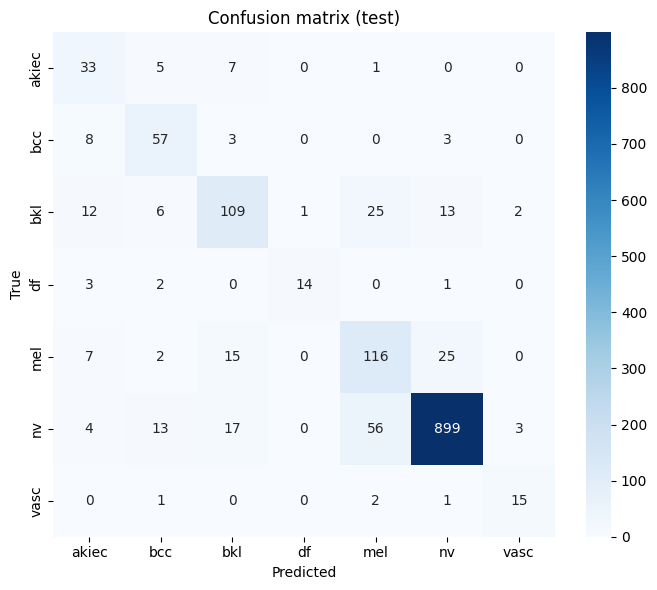

In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns

probs = F.softmax(test_logits / T, dim=1)
preds = probs.argmax(1).numpy(); y = test_labels.numpy()
print(f"Test accuracy: {(preds == y).mean():.3f}\n")
print(classification_report(y, preds, target_names=CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y, preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (test)')
plt.tight_layout(); plt.savefig(f'{WORK}/confusion_matrix.png', dpi=150); plt.show()

In [10]:
vprobs = F.softmax(val_logits / T, dim=1)
vconf, vpred = vprobs.max(1)
vcorrect = vpred.eq(val_labels)

rows = []
for th in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    flag = vconf < th
    rows.append(dict(threshold=th,
                     flagged_pct=round(flag.float().mean().item() * 100, 1),
                     acc_on_confident=round(vcorrect[~flag].float().mean().item(), 3),
                     wrong_caught_pct=round((flag & ~vcorrect).sum().item() / (~vcorrect).sum().item() * 100, 1)))
print(pd.DataFrame(rows))

   threshold  flagged_pct  acc_on_confident  wrong_caught_pct
0        0.4          2.9             0.833               9.8
1        0.5          9.1             0.861              29.7
2        0.6         17.7             0.890              49.6
3        0.7         25.7             0.913              64.1
4        0.8         34.9             0.934              76.1
5        0.9         46.3             0.962              88.8


In [11]:
cfg = json.load(open(f'{WORK}/config.json'))
cfg['temperature'] = T
cfg['uncertainty_threshold'] = 0.60     # change if Step 4 suggests another value
json.dump(cfg, open(f'{WORK}/config.json', 'w'), indent=2)

rep = classification_report(y, preds, target_names=CLASSES, output_dict=True, zero_division=0)
metrics = dict(
    test_accuracy=float((preds == y).mean()),
    test_macro_recall=float(rep['macro avg']['recall']),
    per_class_recall={c: rep[c]['recall'] for c in CLASSES},
    temperature=T,
    ece_test_before=ece_score(F.softmax(test_logits, 1), test_labels),
    ece_test_after=ece_score(F.softmax(test_logits / T, 1), test_labels))
json.dump(metrics, open(f'{WORK}/metrics.json', 'w'), indent=2)
print(json.dumps(metrics, indent=2))
print(sorted(os.listdir(WORK)))

{
  "test_accuracy": 0.8392977717758271,
  "test_macro_recall": 0.7525388166866614,
  "per_class_recall": {
    "akiec": 0.717391304347826,
    "bcc": 0.8028169014084507,
    "bkl": 0.6488095238095238,
    "df": 0.7,
    "mel": 0.703030303030303,
    "nv": 0.90625,
    "vasc": 0.7894736842105263
  },
  "temperature": 1.4906445741653442,
  "ece_test_before": 0.06575587679811423,
  "ece_test_after": 0.019062706768809667
}
['best.pt', 'config.json', 'confusion_matrix.png', 'history.json', 'last.pt', 'metrics.json', 'test.csv', 'train.csv', 'val.csv']


In [12]:
cfg = json.load(open(f'{WORK}/config.json'))
cfg['uncertainty_threshold'] = 0.70      # use 0.60 if you prefer
json.dump(cfg, open(f'{WORK}/config.json', 'w'), indent=2)
print(cfg)

{'class_order': ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'], 'image_size': 224, 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'architecture': 'efficientnet_b0', 'temperature': 1.4906445741653442, 'uncertainty_threshold': 0.7}


In [13]:
%%writefile /content/drive/MyDrive/skinguard/predict.py
"""SkinGuard AI - image classifier.
Usage: from model.predict import predict ; predict(PIL_image) -> dict
Needs model.pt and config.json in the same folder as this file."""
import os, json
import torch, torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image

_DIR = os.path.dirname(os.path.abspath(__file__))
_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_model = None
_cfg = None
_tf = None

def _load():
    global _model, _cfg, _tf
    if _model is not None:
        return
    with open(os.path.join(_DIR, "config.json")) as f:
        _cfg = json.load(f)
    m = models.efficientnet_b0(weights=None)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, len(_cfg["class_order"]))
    m.load_state_dict(torch.load(os.path.join(_DIR, "model.pt"), map_location=_DEVICE))
    _model = m.to(_DEVICE).eval()
    size = _cfg["image_size"]
    _tf = transforms.Compose([
        transforms.Resize((size, size)),
        transforms.ToTensor(),
        transforms.Normalize(_cfg["mean"], _cfg["std"]),
    ])

def predict(image):
    """image: PIL.Image (or a file path). Returns label, confidence, top3, uncertain."""
    _load()
    if isinstance(image, (str, os.PathLike)):
        image = Image.open(image)
    image = image.convert("RGB")
    x = _tf(image).unsqueeze(0).to(_DEVICE)
    with torch.no_grad():
        logits = _model(x).float()
        probs = F.softmax(logits / _cfg["temperature"], dim=1)[0].cpu()
    classes = _cfg["class_order"]
    vals, idx = torch.topk(probs, k=3)
    top3 = [(classes[i], round(float(v), 4)) for v, i in zip(vals.tolist(), idx.tolist())]
    conf = float(vals[0])
    return {
        "label": classes[int(idx[0])],
        "confidence": round(conf, 4),
        "top3": top3,
        "uncertain": bool(conf < _cfg["uncertainty_threshold"]),
    }

Writing /content/drive/MyDrive/skinguard/predict.py


In [14]:
import shutil, sys, importlib
from PIL import Image

shutil.copy(f'{WORK}/best.pt', f'{WORK}/model.pt')
sys.path.insert(0, WORK)
import predict as P
importlib.reload(P)

# 1) matches the notebook's own probabilities
r0 = P.predict(Image.open(te.iloc[0].path))
print("Match with evaluation:", abs(r0['confidence'] - probs[0].max().item()) < 1e-3)

# 2) 10 test images
sample = te.sample(10, random_state=1)
ok = 0
for _, r in sample.iterrows():
    out = P.predict(Image.open(r.path))
    ok += (out['label'] == r.dx)
    print(r.dx, '->', out['label'], out['confidence'], out['uncertain'], out['top3'])
print("Correct:", ok, "/ 10")

# 3) exact dictionary shape and odd inputs
assert set(out.keys()) == {'label', 'confidence', 'top3', 'uncertain'}
P.predict(Image.new('L', (50, 50)))          # grayscale
P.predict(Image.new('RGBA', (3000, 2000)))   # RGBA, large
P.predict(sample.iloc[0].path)               # file path
print("Edge cases OK")

Match with evaluation: True
mel -> mel 0.8218 False [('mel', 0.8218), ('nv', 0.1287), ('bcc', 0.0247)]
nv -> nv 0.9834 False [('nv', 0.9834), ('df', 0.0086), ('vasc', 0.0024)]
bkl -> mel 0.72 False [('mel', 0.72), ('nv', 0.2346), ('bkl', 0.027)]
nv -> mel 0.8259 False [('mel', 0.8259), ('nv', 0.0989), ('df', 0.0297)]
nv -> nv 0.8478 False [('nv', 0.8478), ('df', 0.0757), ('mel', 0.0336)]
nv -> nv 0.9918 False [('nv', 0.9918), ('df', 0.0036), ('bcc', 0.0014)]
akiec -> akiec 0.9336 False [('akiec', 0.9336), ('bkl', 0.058), ('mel', 0.0042)]
mel -> mel 0.6167 True [('mel', 0.6167), ('bkl', 0.1807), ('bcc', 0.0793)]
mel -> bkl 0.3892 True [('bkl', 0.3892), ('nv', 0.3573), ('mel', 0.1893)]
nv -> nv 0.8176 False [('nv', 0.8176), ('mel', 0.0676), ('vasc', 0.0639)]
Correct: 7 / 10
Edge cases OK


In [15]:
import torchvision, PIL
open(f'{WORK}/requirements.txt', 'w').write(
    f"torch=={torch.__version__.split('+')[0]}\ntorchvision=={torchvision.__version__.split('+')[0]}\npillow=={PIL.__version__}\n")

H = '/content/handover'
shutil.rmtree(H, ignore_errors=True); os.makedirs(H + '/samples'); os.makedirs(H + '/results')
for f in ['predict.py', 'config.json', 'requirements.txt']:
    shutil.copy(f'{WORK}/{f}', H)
for f in ['metrics.json', 'confusion_matrix.png', 'history.json']:
    shutil.copy(f'{WORK}/{f}', H + '/results')

rows = []
for _, r in sample.iterrows():
    name = f"{r.image_id}.jpg"
    shutil.copy(r.path, f'{H}/samples/{name}')
    out = P.predict(Image.open(r.path))
    rows.append(dict(file=name, true=r.dx, pred=out['label'],
                     confidence=out['confidence'], uncertain=out['uncertain']))
pd.DataFrame(rows).to_csv(H + '/samples/expected_predictions.csv', index=False)

shutil.make_archive('/content/model_handover', 'zip', H)
from google.colab import files
files.download('/content/model_handover.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>